In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

price_files = {
    -2: "../data2/prices_round_2_day_-1.csv",
    -1: "../data2/prices_round_2_day_0.csv",
}

trade_files = {
    -2: "../data2/trades_round_2_day_-1.csv",
    -1: "../data2/trades_round_2_day_0.csv",
}

price_frames = []
trade_frames = []

for day, path in price_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    price_frames.append(frame)

for day, path in trade_files.items():
    frame = pd.read_csv(path, sep=";")
    frame["day"] = day
    trade_frames.append(frame)

prices = pd.concat(price_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)
trades = pd.concat(trade_frames, ignore_index=True).sort_values(["day", "timestamp"]).reset_index(drop=True)

def prepare_product_context(product: str):
    price_cols = [
        "day",
        "timestamp",
        "product",
        "bid_price_1",
        "bid_volume_1",
        "ask_price_1",
        "ask_volume_1",
        "mid_price",
        "profit_and_loss",
    ]
    price_cols = [col for col in price_cols if col in prices.columns]

    price_prod = prices.loc[prices["product"] == product, price_cols].copy().sort_values(["day", "timestamp"])
    price_prod = price_prod[price_prod["mid_price"] > 0].copy()
    if {"bid_price_1", "ask_price_1"}.issubset(price_prod.columns):
        price_prod["spread_1"] = price_prod["ask_price_1"] - price_prod["bid_price_1"]
    else:
        price_prod["spread_1"] = np.nan
    price_prod["mid_change_1"] = price_prod.groupby("day")["mid_price"].shift(-1) - price_prod["mid_price"]
    price_prod["mid_change_5"] = price_prod.groupby("day")["mid_price"].shift(-5) - price_prod["mid_price"]
    price_prod["return_1"] = price_prod.groupby("day")["mid_price"].pct_change()

    trade_prod = trades.loc[trades["symbol"] == product, ["day", "timestamp", "price", "quantity"]].copy().sort_values(["day", "timestamp"])
    merged_frames = []
    for day in sorted(trade_prod["day"].dropna().unique().tolist()):
        trade_day = trade_prod[trade_prod["day"] == day].sort_values("timestamp")
        price_day = price_prod[price_prod["day"] == day].drop(columns=["day"]).sort_values("timestamp")
        if trade_day.empty or price_day.empty:
            continue
        merged_day = pd.merge_asof(
            trade_day,
            price_day,
            on="timestamp",
            direction="backward",
        )
        merged_frames.append(merged_day)

    trade_ctx = pd.concat(merged_frames, ignore_index=True) if merged_frames else trade_prod.copy()
    if "mid_price" not in trade_ctx.columns:
        for col in ["mid_price", "spread_1", "mid_change_1", "mid_change_5", "return_1"]:
            trade_ctx[col] = np.nan

    trade_ctx["slippage_vs_mid"] = trade_ctx["price"] - trade_ctx["mid_price"]
    trade_ctx["abs_slippage"] = trade_ctx["slippage_vs_mid"].abs()
    trade_ctx["trade_side_est"] = np.where(
        trade_ctx["slippage_vs_mid"] > 0,
        "buy_aggressive",
        np.where(trade_ctx["slippage_vs_mid"] < 0, "sell_aggressive", "at_mid"),
    )
    trade_ctx["realized_edge_1"] = np.where(
        trade_ctx["trade_side_est"] == "buy_aggressive",
        trade_ctx["mid_change_1"] - trade_ctx["slippage_vs_mid"],
        np.where(
            trade_ctx["trade_side_est"] == "sell_aggressive",
            -trade_ctx["mid_change_1"] + trade_ctx["slippage_vs_mid"],
            np.nan,
        ),
    )
    trade_ctx["time_bucket"] = pd.qcut(trade_ctx["timestamp"], q=4, labels=False, duplicates="drop")

    return price_prod, trade_ctx

ash_price_prod, ash_trade_ctx = prepare_product_context("ASH_COATED_OSMIUM")
pepper_price_prod, pepper_trade_ctx = prepare_product_context("INTARIAN_PEPPER_ROOT")

In [3]:
ash_price_summary = ash_price_prod.groupby("day").agg(
    trade_count=("mid_price", "count"),
    mid_mean=("mid_price", "mean"),
    mid_median=("mid_price", "median"),
    mid_std=("mid_price", "std"),
    spread_mean=("spread_1", "mean"),
    spread_p90=("spread_1", lambda s: s.quantile(0.90)),
    return_autocorr_lag1=("return_1", lambda s: s.autocorr(lag=1)),
    return_autocorr_lag5=("return_1", lambda s: s.autocorr(lag=5)),
    avg_bid_vol_1=("bid_volume_1", "mean"),
    avg_ask_vol_1=("ask_volume_1", "mean"),
).reset_index()

ash_trade_summary = ash_trade_ctx.groupby("day").agg(
    trade_count=("price", "count"),
    total_quantity=("quantity", "sum"),
    abs_quantity=("quantity", lambda s: s.abs().sum()),
    vwap=("price", lambda s: np.average(s, weights=ash_trade_ctx.loc[s.index, "quantity"].abs())),
    trade_price_mean=("price", "mean"),
    trade_price_std=("price", "std"),
    slippage_mean=("slippage_vs_mid", "mean"),
    slippage_median=("slippage_vs_mid", "median"),
    abs_slippage_mean=("abs_slippage", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
    realized_edge_median=("realized_edge_1", "median"),
).reset_index()

ash_side_summary = ash_trade_ctx.groupby(["day", "trade_side_est"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    slippage_mean=("slippage_vs_mid", "mean"),
    abs_slippage_mean=("abs_slippage", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

ash_time_summary = ash_trade_ctx.groupby(["day", "time_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    mid_mean=("mid_price", "mean"),
    slippage_mean=("slippage_vs_mid", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

ash_slippage_summary = ash_trade_ctx.copy()
ash_slippage_summary["slippage_bucket"] = pd.cut(
    ash_slippage_summary["slippage_vs_mid"],
    bins=[-np.inf, -6, -3, -1, 0, 1, 3, 6, np.inf],
    labels=["<=-6", "-6:-3", "-3:-1", "-1:0", "0:1", "1:3", "3:6", ">=6"],
)

ash_slippage_bucket_summary = ash_slippage_summary.groupby(["day", "slippage_bucket"]).agg(
    trade_count=("price", "count"),
    quantity_sum=("quantity", "sum"),
    price_mean=("price", "mean"),
    mid_mean=("mid_price", "mean"),
    future_move_1_mean=("mid_change_1", "mean"),
    future_move_5_mean=("mid_change_5", "mean"),
    realized_edge_mean=("realized_edge_1", "mean"),
).reset_index()

display(ash_price_summary)
display(ash_trade_summary)
display(ash_side_summary)
display(ash_time_summary)
display(ash_slippage_bucket_summary)

,day,trade_count,mid_mean,mid_median,mid_std,spread_mean,spread_p90,return_autocorr_lag1,return_autocorr_lag5,avg_bid_vol_1,avg_ask_vol_1
0,-2,9985,10000.825088,10001.0,4.466929,16.223990,19.0,-0.506304,0.006528,14.184457,14.225182
1,-1,9984,10001.607372,10002.0,5.659611,16.249541,19.0,-0.506367,-0.003807,14.311213,14.184897


,day,trade_count,total_quantity,abs_quantity,vwap,trade_price_mean,trade_price_std,slippage_mean,slippage_median,abs_slippage_mean,realized_edge_mean,realized_edge_median
0,-2,459,2348,2348,10001.050681,10000.882353,8.970798,-0.342048,0.0,7.910675,-8.103604,-8.0
1,-1,471,2404,2404,10001.105657,10000.983015,9.825917,-0.251592,0.0,7.710191,-7.993333,-8.0


,day,trade_side_est,trade_count,quantity_sum,price_mean,slippage_mean,abs_slippage_mean,realized_edge_mean
0,-2,at_mid,15,74,10003.600000,0.000000,0.000000,NaN
1,-2,buy_aggressive,215,1118,10008.925581,8.079070,8.079070,-8.111628
2,-2,sell_aggressive,229,1156,9993.152838,-8.270742,8.270742,-8.096070
3,-1,at_mid,21,105,10002.000000,0.000000,0.000000,NaN
4,-1,buy_aggressive,221,1152,10009.072398,7.947964,7.947964,-7.889140
5,-1,sell_aggressive,229,1147,9993.082969,-8.187773,8.187773,-8.093886


,day,time_bucket,trade_count,quantity_sum,price_mean,mid_mean,slippage_mean,realized_edge_mean
0,-2,0,114,579,9999.631579,10000.820175,-1.188596,-8.732143
1,-2,1,114,595,10002.763158,10002.921053,-0.157895,-8.290909
2,-2,2,115,584,10002.191304,10002.826087,-0.634783,-7.718182
3,-2,3,116,590,9998.965517,9998.366379,0.599138,-7.669643
4,-1,0,120,608,10000.325000,10001.058333,-0.733333,-8.387931
5,-1,1,117,602,10001.572650,10001.666667,-0.094017,-8.252174
6,-1,2,117,595,9999.119658,9999.474359,-0.354701,-7.798165
7,-1,3,117,599,10002.931624,10002.743590,0.188034,-7.500000


,day,slippage_bucket,trade_count,quantity_sum,price_mean,mid_mean,future_move_1_mean,future_move_5_mean,realized_edge_mean
0,-2,<=-6,219,1117,9993.000000,10001.431507,-0.105023,-0.479452,-8.326484
1,-2,-6:-3,10,39,9996.500000,10001.250000,-1.700000,-1.950000,-3.050000
2,-2,-1:0,15,74,10003.600000,10003.600000,-2.466667,-1.933333,NaN
3,-2,1:3,3,14,9997.000000,9994.166667,7.833333,7.333333,5.000000
4,-2,3:6,16,64,10005.062500,10000.250000,1.718750,1.218750,-3.093750
5,-2,>=6,196,1040,10009.423469,10000.997449,-0.295918,0.354592,-8.721939
6,-1,<=-6,215,1099,9992.683721,10001.141860,-0.058140,-0.062791,-8.400000
7,-1,-6:-3,13,46,10000.384615,10004.538462,-1.115385,-0.307692,-3.038462
8,-1,-3:-1,1,2,9984.000000,9986.500000,5.500000,2.500000,-8.000000
9,-1,-1:0,21,105,10002.000000,10002.000000,-0.833333,-0.333333,NaN


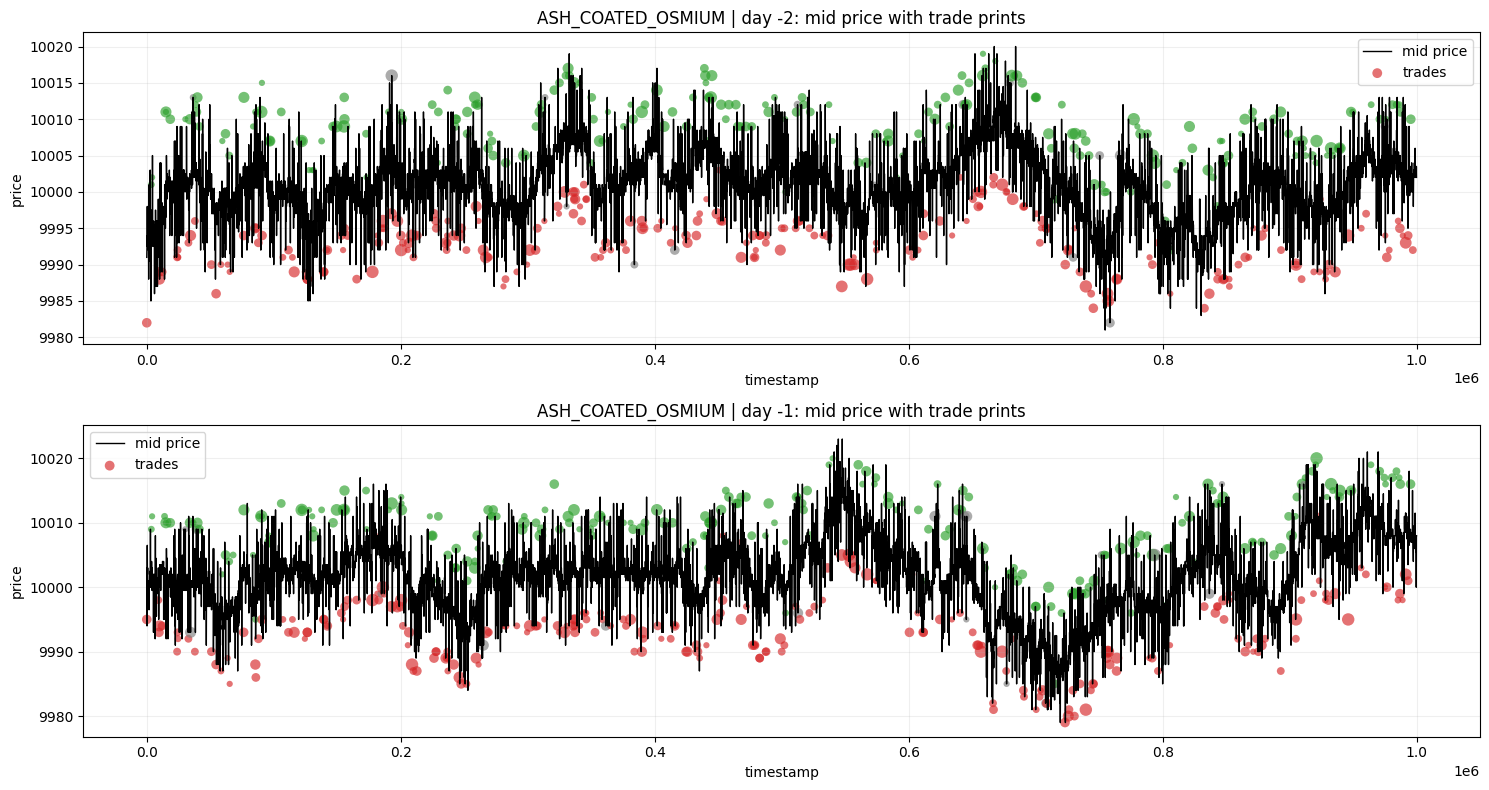

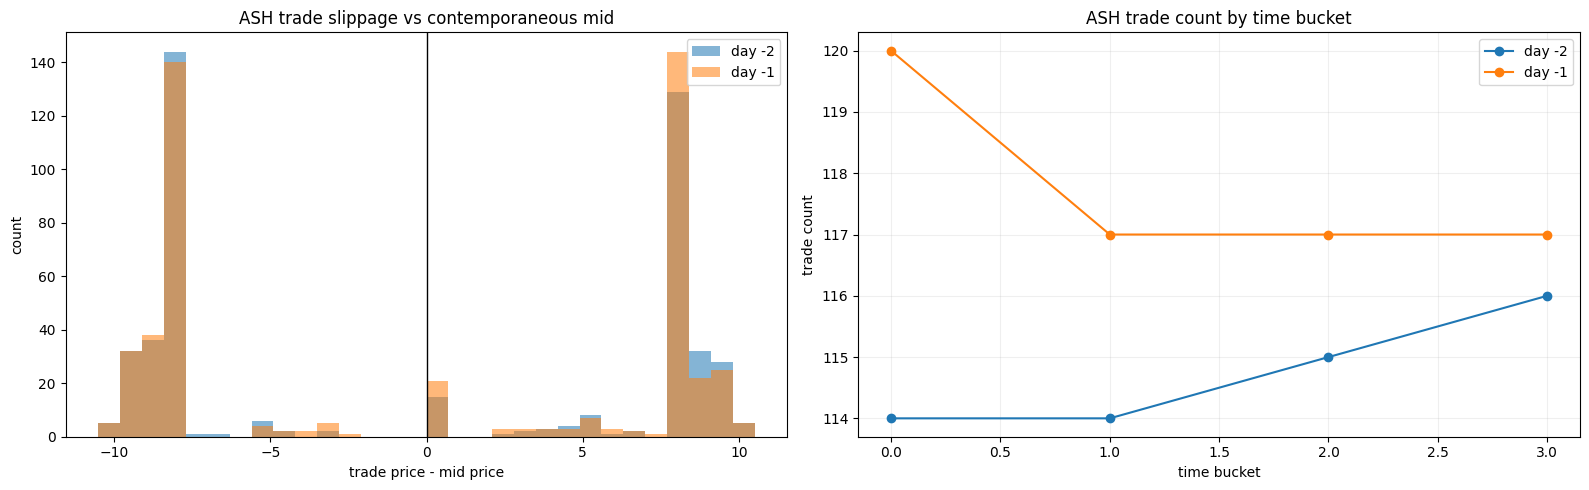

In [4]:
days = sorted(ash_price_prod["day"].dropna().unique().tolist())
fig, axes = plt.subplots(len(days), 1, figsize=(15, 4 * len(days)), sharex=False)
if len(days) == 1:
    axes = [axes]

for ax, day in zip(axes, days):
    price_day = ash_price_prod[ash_price_prod["day"] == day]
    trade_day = ash_trade_ctx[ash_trade_ctx["day"] == day]

    ax.plot(price_day["timestamp"], price_day["mid_price"], color="black", linewidth=1.0, label="mid price")
    if not trade_day.empty:
        colors = np.where(trade_day["trade_side_est"] == "buy_aggressive", "tab:green", np.where(trade_day["trade_side_est"] == "sell_aggressive", "tab:red", "tab:gray"))
        sizes = np.clip(trade_day["quantity"].abs() * 8, 20, 220)
        ax.scatter(trade_day["timestamp"], trade_day["price"], s=sizes, c=colors, alpha=0.65, edgecolors="none", label="trades")
    ax.set_title(f"ASH_COATED_OSMIUM | day {day}: mid price with trade prints")
    ax.set_xlabel("timestamp")
    ax.set_ylabel("price")
    ax.grid(alpha=0.2)
    ax.legend(loc="best")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for day in days:
    slippage_day = ash_trade_ctx[ash_trade_ctx["day"] == day]["slippage_vs_mid"].dropna()
    axes[0].hist(slippage_day, bins=30, alpha=0.55, label=f"day {day}")
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("ASH trade slippage vs contemporaneous mid")
axes[0].set_xlabel("trade price - mid price")
axes[0].set_ylabel("count")
axes[0].legend()

time_counts = ash_trade_ctx.groupby(["day", "time_bucket"]).size().reset_index(name="trade_count")
for day in days:
    subset = time_counts[time_counts["day"] == day]
    axes[1].plot(subset["time_bucket"], subset["trade_count"], marker="o", label=f"day {day}")
axes[1].set_title("ASH trade count by time bucket")
axes[1].set_xlabel("time bucket")
axes[1].set_ylabel("trade count")
axes[1].legend()
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()